# 05 · Explainability: why did this alert fire?

Explains the **deployed model** — the federated XGBoost (equal client scaling + k-of-n peer-validation gate) — not a separate centralised one.

| Section | What |
|---|---|
| 1–2 | Train and **save** the federated model (`models/fed_xgb/`): the artifact deployment will load |
| 3 | **Exact TreeSHAP for the federated ensemble** — SHAP is additive over trees, so the ensemble's explanation is the scaled sum of each client update's SHAP values (checked numerically) |
| 4 | **8 feature groups** an operator can read (association setup, rejects & AE titles, PDU anomalies, outbound / inbound volume, DICOM data transfer, size & timing, scanning) — collinear features (e.g. `n_called_ae` / `n_calling_ae`, r = 0.998) share credit inside a group instead of splitting it arbitrarily |
| 5 | **Class signatures:** which groups drive each class; sanity check against what each attack actually does |
| 6 | **Per-alert explanation:** one sentence per alert from a class template, with the feature values vs. the benign median, plus a **consistency flag** — and whether that flag helps spot false alarms |
| 7 | **Deletion test (faithfulness):** remove the top-k groups (set to benign medians) → does the alert disappear faster than when removing random groups? |
| 8 | **Agreement:** do XGBoost and an MLP rely on the same groups? (model-agnostic group occlusion, Spearman) |

Logged to MLflow, experiment **vitalgate-xai**. Runtime ≈ 15–25 min.

In [1]:
# 0 · Setup
import os, sys, json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import spearmanr, norm
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import f1_score, recall_score
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import QuantileTransformer
import xgboost as xgb
try:
    from IPython.display import display
except ImportError:
    display = print
warnings.filterwarnings("ignore")

FAST = False
SEED = 0
REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROC, MODELS = REPO / "data" / "processed", REPO / "models"
FEDDIR = MODELS / "fed_xgb"; FEDDIR.mkdir(parents=True, exist_ok=True)
REP = REPO / "reports" / "xai"; REP.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(REPO / "src"))
import tracking, mlflow
tracking.use_experiment("vitalgate-xai")
plt.rcParams["figure.dpi"] = 110
print("xgboost", xgb.__version__, "| session", tracking.SESSION)

xgboost 3.4.1 | session 20261114-211803


## 1 · Data

In [2]:
CFG = json.loads((MODELS / "xgb_config.json").read_text(encoding="utf-8"))
FED = json.loads((MODELS / "fed_config.json").read_text(encoding="utf-8"))
FEATURES = CFG["features"]; F = len(FEATURES)
ROLL_BASE = CFG["rolling"]["base"]; ROLL_FEATS = [f"{b}_roll3" for b in ROLL_BASE]
RULE_CLASS = CFG["rule_class"]
win = pd.read_parquet(PROC / "windows_v2.parquet")
import features as FV
d = FV.add_history(win[win["label_class"] != RULE_CLASS].reset_index(drop=True), "split_run")   # v3
le = LabelEncoder().fit(d["label_class"]); CLS = list(le.classes_); K = len(CLS); BEN = CLS.index("benign")
ATTACKS = [c for c in CLS if c != "benign"]
y = le.transform(d["label_class"]); X = d[FEATURES].to_numpy(np.float32)
TR, VA, TE = [(d["split_run"] == p).values for p in ("train", "val", "test")]
SITES = sorted(d["site"].unique()); site_mask = {s: (d["site"] == s).values for s in SITES}
BENIGN_MEDIAN = pd.Series(np.nanmedian(X[TR & (y == BEN)], axis=0), index=FEATURES)   # reference values for explanations
print(F, "features |", CLS)

95 features | ['ae_bruteforce', 'assoc_flood', 'benign', 'exfiltration', 'malformed_pdu', 'ransomware_like', 'recon']


## 2 · Train and save the federated model (equal scaling + k-of-n gate)
Same protocol as notebooks 03–04, no attacker. Every accepted client update (10 trees) is saved with its scale; the model is `prior + Σ scale × update`.

In [3]:
LT, MAXR, PAT = FED["local_trees"], (40 if FAST else FED["max_rounds"]), FED["patience"]
TOL = 0.002
def params(seed):
    return dict(objective="multi:softprob", num_class=K, max_depth=FED["xgb"]["max_depth"], eta=FED["xgb"]["eta"],
                subsample=0.8, colsample_bytree=0.8, tree_method="hist", seed=int(seed), nthread=os.cpu_count() or 4)
def dmat(Xa, ya=None, w=None, margin=None):
    if margin is None: return xgb.DMatrix(Xa, label=ya, weight=w)
    try:    return xgb.DMatrix(Xa, label=ya, weight=w, base_margin=margin)
    except Exception: return xgb.DMatrix(Xa, label=ya, weight=w, base_margin=margin.ravel())
def zeros(n): return np.zeros((n, K), np.float32)
def contrib(b, Xa): return b.predict(dmat(Xa, margin=zeros(len(Xa))), output_margin=True).reshape(len(Xa), K)
def softmax(m): e = np.exp(m - m.max(1, keepdims=True)); return e / e.sum(1, keepdims=True)
def bal_logloss(yv, P):
    p = np.clip(P[np.arange(len(yv)), yv], 1e-7, 1); return float(np.mean([-np.log(p[yv == c]).mean() for c in np.unique(yv)]))

clients = [(X[TR & site_mask[s]], y[TR & site_mask[s]]) for s in SITES]
cvals = [(X[VA & site_mask[s]], y[VA & site_mask[s]]) for s in SITES]
n = len(clients)
counts = sum(np.bincount(yc, minlength=K) for _, yc in clients)
PRIOR = np.log(np.maximum(counts, 1) / counts.sum()).astype(np.float32)
w_cls = (counts.max() / np.maximum(counts, 1)) ** 0.5 if FED["xgb"]["class_weights"] == "sqrt" else np.ones(K)
m_tr = [np.tile(PRIOR, (len(yc), 1)) for _, yc in clients]; m_cv = [np.tile(PRIOR, (len(yv), 1)) for _, yv in cvals]
m_va = np.tile(PRIOR, (VA.sum(), 1))
UPDATES, best, since = [], dict(f1=-1, round=0, k=0), 0
for t in range(1, MAXR + 1):
    for i, (Xc, yc) in enumerate(clients):
        b = xgb.train(params(SEED * 1000 + t * 10 + i), dmat(Xc, yc, w_cls[yc], m_tr[i]), LT)
        dv = [contrib(b, cvals[j][0]) for j in range(n)]
        deltas = [bal_logloss(cvals[j][1], softmax(m_cv[j] + dv[j] / n)) - bal_logloss(cvals[j][1], softmax(m_cv[j])) for j in range(n) if j != i]
        if np.sum(np.array(deltas) <= TOL) < max(1, n - 2):          # k-of-n gate, f = 1
            continue
        UPDATES.append(dict(round=t, client=SITES[i], booster=b, scale=1.0 / n))
        for k, (Xk, _) in enumerate(clients): m_tr[k] += contrib(b, Xk) / n
        for k in range(n): m_cv[k] += dv[k] / n
        m_va += contrib(b, X[VA]) / n
    f1 = f1_score(y[VA], m_va.argmax(1), average="macro")
    if f1 > best["f1"] + 1e-4: best, since = dict(f1=f1, round=t, k=len(UPDATES)), 0
    else:
        since += 1
        if since >= PAT: break
UPDATES = UPDATES[:best["k"]]
print(f"best round {best['round']} | {len(UPDATES)} accepted updates | val macro-F1 {best['f1']:.4f}")

for j, u in enumerate(UPDATES):
    u["booster"].save_model(FEDDIR / f"update_{j:03d}.json")
manifest = dict(classes=CLS, features=FEATURES, prior=PRIOR.tolist(), method=FED["method"], defence="k-of-n peer validation gate (f=1, tol=0.002)",
                updates=[dict(file=f"update_{j:03d}.json", round=u["round"], client=u["client"], scale=u["scale"]) for j, u in enumerate(UPDATES)])
(FEDDIR / "manifest.json").write_text(json.dumps(manifest, indent=1), encoding="utf-8")
FED["defence"] = dict(name="gate-kofn", f_assumed=1, tol=TOL, notebook04={"clean_macroF1": 0.926, "worst_attack_macroF1": 0.923,
                                                                          "honest_rejected": "0-2%", "malicious_rejected": "77-97%"})
(MODELS / "fed_config.json").write_text(json.dumps(FED, indent=2), encoding="utf-8")

def fed_margin(Xa):
    m = np.tile(PRIOR, (len(Xa), 1))
    for u in UPDATES: m += u["scale"] * contrib(u["booster"], Xa)
    return m
P_TE = softmax(fed_margin(X[TE])); PRED = P_TE.argmax(1)
print(f"test macro-F1 {f1_score(y[TE], PRED, average='macro'):.4f}  (notebook 03: 0.926)")

best round 14 | 38 accepted updates | val macro-F1 0.9633
test macro-F1 0.9412  (notebook 03: 0.926)


## 3 · Exact SHAP for the federated ensemble
`margin(x) = prior + Σᵤ scaleᵤ · (Σ_f φᵤ,f(x) + biasᵤ)` — so the ensemble's SHAP value for feature f is Σᵤ scaleᵤ · φᵤ,f(x). Checked: rebuilt margins must equal the model's margins.

In [4]:
def fed_shap(Xa):
    phi = np.zeros((len(Xa), K, F + 1))
    for u in UPDATES:
        c = u["booster"].predict(dmat(Xa, margin=zeros(len(Xa))), pred_contribs=True)
        phi += u["scale"] * np.asarray(c).reshape(len(Xa), K, F + 1)
    return phi[:, :, :F], phi[:, :, F] + PRIOR          # feature contributions, base value

PHI, BASE = fed_shap(X[TE])
err = np.abs(PHI.sum(2) + BASE - fed_margin(X[TE])).max()
print(f"additivity check: max |rebuilt − model margin| = {err:.2e}  ->", "OK" if err < 1e-3 else "CHECK")

additivity check: max |rebuilt − model margin| = 3.78e-06  -> OK


## 4 · Feature groups

In [5]:
GROUPS = {
    "Association setup":     ["assoc_rq", "assoc_ac", "release", "abort", "assoc_accept_ratio", "assoc_rq_roll3"],
    "Rejects & AE titles":   ["assoc_rj", "n_called_ae", "n_calling_ae"],
    "PDU anomalies":         ["bad_first_pdu", "big_pdu_len"],
    "Outbound volume":       ["out_pkts", "out_bytes", "out_pkts_roll3", "out_bytes_roll3", "out_in_byte_ratio"],
    "Inbound volume":        ["in_pkts", "in_bytes"],
    "DICOM data transfer":   ["pdata_pkts", "pdata_pkts_roll3"],
    "Packet size & timing":  ["mean_pkt", "std_pkt", "bytes_per_pkt", "mean_iat_ms", "std_iat_ms", "mean_iat_ms_roll3"],
    "Scanning / TCP flags":  ["syn", "rst", "fin", "rst_syn_ratio", "n_dst_ports", "n_src_ports"],
}
GROUPS["Packet size & timing"] = GROUPS["Packet size & timing"] + ["gap_s", "gap_lag1"]
GROUPS = {gname: [f for f in FEATURES if FV.feature_group_of(f, {gname: fs}) == gname] for gname, fs in GROUPS.items()}   # v3: lags join their base feature's group
missing = set(FEATURES) - {f for v in GROUPS.values() for f in v}; extra = {f for v in GROUPS.values() for f in v} - set(FEATURES)
assert not missing and not extra, (missing, extra)
GN = list(GROUPS); G = len(GN)
GIDX = {gname: [FEATURES.index(f) for f in fs] for gname, fs in GROUPS.items()}
def to_groups(phi):           # (n, K, F) -> (n, K, G)
    return np.stack([phi[:, :, GIDX[gname]].sum(2) for gname in GN], axis=2)
PHI_G = to_groups(PHI)
pd.Series({gname: len(fs) for gname, fs in GROUPS.items()}, name="features per group")

Association setup       17
Rejects & AE titles      9
PDU anomalies            6
Outbound volume         15
Inbound volume           8
DICOM data transfer      5
Packet size & timing    17
Scanning / TCP flags    18
Name: features per group, dtype: int64

## 5 · Class signatures and sanity check
Mean group SHAP **towards the true class**, over correctly detected test windows of that class. Expected groups come from what each attack does (EDA): a good explanation should name them.

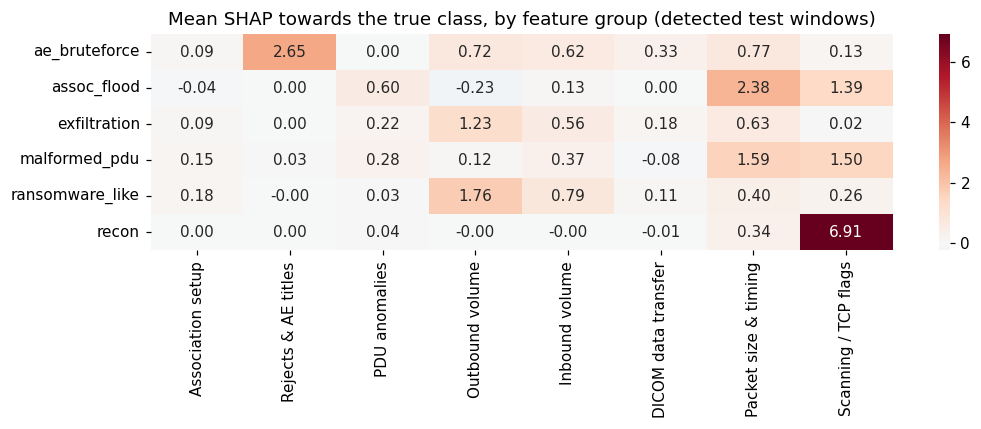

,windows,top1_in_expected,top2_hits_expected,most_common_top1
ae_bruteforce,486,0.963,0.967,Rejects & AE titles
assoc_flood,440,0.016,0.977,Packet size & timing
exfiltration,210,0.843,0.971,Outbound volume
malformed_pdu,346,0.000,0.040,Packet size & timing
ransomware_like,339,0.988,1.000,Outbound volume
recon,415,0.990,0.990,Scanning / TCP flags


In [6]:
EXPECTED = {
    "recon":           {"Scanning / TCP flags"},
    "ae_bruteforce":   {"Rejects & AE titles", "Association setup"},
    "assoc_flood":     {"Association setup", "PDU anomalies", "Scanning / TCP flags"},
    "malformed_pdu":   {"PDU anomalies"},
    "exfiltration":    {"Inbound volume", "Outbound volume", "DICOM data transfer"},
    "ransomware_like": {"Outbound volume", "DICOM data transfer", "Inbound volume"},
}
yt = y[TE]
sig, match = {}, {}
for c in ATTACKS:
    ci = CLS.index(c); m = (yt == ci) & (PRED == ci)
    if m.sum() == 0: continue
    v = PHI_G[m, ci, :]; sig[c] = v.mean(0)
    top1 = np.array(GN)[v.argmax(1)]; top2 = np.array(GN)[np.argsort(-v, 1)[:, :2]]
    match[c] = dict(windows=int(m.sum()), top1_in_expected=np.mean([t in EXPECTED[c] for t in top1]),
                    top2_hits_expected=np.mean([len(set(t) & EXPECTED[c]) > 0 for t in top2]),
                    most_common_top1=pd.Series(top1).mode()[0])
SIG = pd.DataFrame(sig, index=GN).T
plt.figure(figsize=(10, 4)); sns.heatmap(SIG, annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Mean SHAP towards the true class, by feature group (detected test windows)"); plt.tight_layout()
plt.savefig(REP / "class_signatures.png"); plt.show()
MATCH = pd.DataFrame(match).T; MATCH[["top1_in_expected", "top2_hits_expected"]] = MATCH[["top1_in_expected", "top2_hits_expected"]].astype(float).round(3)
display(MATCH)

## 6 · Per-alert explanation, template sentence and consistency flag
Each alert gets: the predicted class, its probability, the top-3 groups pushing towards it, and inside the top group the feature with the largest push, shown against the benign median.
**Consistency flag** = the top group is one of the class's expected groups. If false alarms are flagged inconsistent much more often than true alerts, the flag is a useful triage signal.

In [7]:
HEADLINE = {"recon": "Port scan / service discovery", "ae_bruteforce": "AE-title guessing (brute force)",
            "assoc_flood": "DICOM association flood", "malformed_pdu": "Malformed DICOM PDUs",
            "exfiltration": "Possible bulk data exfiltration", "ransomware_like": "Mass write activity (ransomware-like)"}

def explain(row_te, k=3):
    ci = PRED[row_te]; c = CLS[ci]
    gv = PHI_G[row_te, ci, :]; order = np.argsort(-gv)[:k]
    parts = []
    for gi in order:
        if gv[gi] <= 0: break
        idx = GIDX[GN[gi]]; fi = idx[int(np.argmax(PHI[row_te, ci, idx]))]; f = FEATURES[fi]
        fname = f.replace("_lag1", " (previous window)").replace("_lag2", " (2 windows ago)")
        parts.append(f"{GN[gi]} ({fname} = {X[TE][row_te, fi]:.4g}, benign median {BENIGN_MEDIAN[f]:.4g})")
    consistent = GN[order[0]] in EXPECTED.get(c, set())
    detail = "; ".join(parts) if parts else "no single feature group stands out (weak, spread-out evidence)"
    return dict(predicted=c, prob=float(P_TE[row_te, ci]), consistent=consistent, top_groups=[GN[i] for i in order],
                sentence=f"{HEADLINE.get(c, c)} (p={P_TE[row_te, ci]:.2f}) — {detail}" + ("" if consistent else "  [explanation unusual for this class: review]"))

alerts = np.where(PRED != BEN)[0]
EXPL = pd.DataFrame([dict(row=i, true=CLS[yt[i]], **explain(i)) for i in alerts])
EXPL["correct"] = EXPL["true"] == EXPL["predicted"]
EXPL["false_alarm"] = EXPL["true"] == "benign"

print("Example explanations (one correct alert per class + false alarms):")
ex = pd.concat([EXPL[EXPL.correct & (EXPL.predicted == c)].head(1) for c in ATTACKS] + [EXPL[EXPL.false_alarm].head(3)])
for _, r in ex.iterrows():
    print(f"\n[{'OK' if r.correct else 'WRONG'} | true={r.true} | p={r.prob:.2f}] {r.sentence}")

flag = pd.DataFrame({
    "alerts": EXPL.groupby(np.where(EXPL.false_alarm, "false alarm (benign)", np.where(EXPL.correct, "correct alert", "wrong attack class"))).size(),
    "flagged inconsistent %": EXPL.groupby(np.where(EXPL.false_alarm, "false alarm (benign)", np.where(EXPL.correct, "correct alert", "wrong attack class")))["consistent"].apply(lambda s: round((~s).mean() * 100, 1))})
print("\nConsistency flag by alert type:"); display(flag)
EXPL.to_csv(REP / "alert_explanations_test.csv", index=False, encoding="utf-8-sig")

Example explanations (one correct alert per class + false alarms):

[OK | true=ae_bruteforce | p=0.99] AE-title guessing (brute force) (p=0.99) — Rejects & AE titles (assoc_rj = 424, benign median 0); Association setup (assoc_rq = 456, benign median 1); DICOM data transfer (pdata_pkts = 0, benign median 19)

[OK | true=assoc_flood | p=1.00] DICOM association flood (p=1.00) — Packet size & timing (bytes_per_pkt = 56.06, benign median 4408); Scanning / TCP flags (n_src_ports = 56, benign median 1); Inbound volume (in_bytes_sum300s = 5824, benign median 2.002e+05)  [explanation unusual for this class: review]

[OK | true=exfiltration | p=0.80] Possible bulk data exfiltration (p=0.80) — Outbound volume (out_in_byte_ratio = 0.189, benign median 140.8); Association setup (assoc_rq_sum300s = 3, benign median 21); Inbound volume (in_bytes_sum300s = 3.033e+05, benign median 2.002e+05)

[OK | true=malformed_pdu | p=1.00] Malformed DICOM PDUs (p=1.00) — Scanning / TCP flags (rst = 1, benign media

,alerts,flagged inconsistent %
correct alert,2236,37.5
false alarm (benign),25,20.0
wrong attack class,83,4.8


## 7 · Deletion test (are the explanations faithful?)
For correctly detected attack windows: replace the top-k groups' features with benign medians and re-score. Compare with replacing k **random** groups (5 draws). Faithful explanations make the alert collapse much faster.

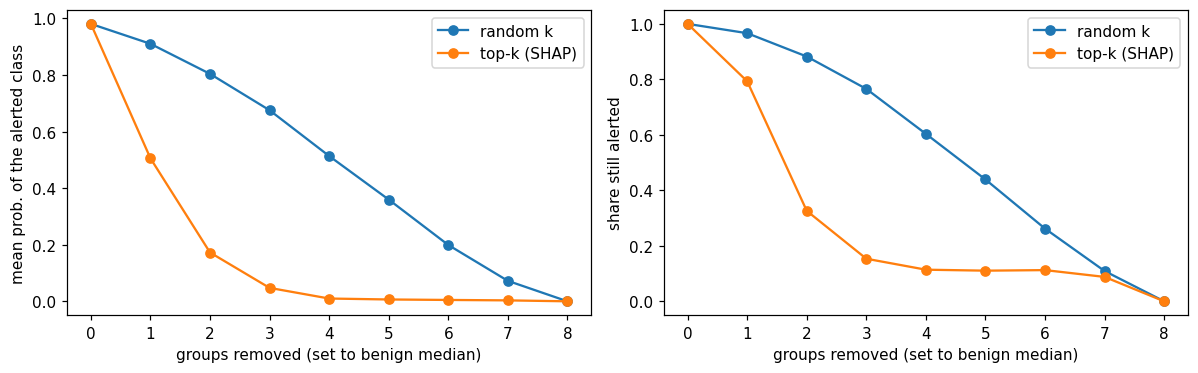

AOPC (mean drop in alerted-class probability over k = 1..8; higher = more faithful):


method
random k        0.539
top-k (SHAP)    0.886
dtype: float32

method,random k,top-k (SHAP)
k,,
0,1.000,1.000
1,0.966,0.793
2,0.882,0.326
3,0.766,0.154


In [8]:
rng = np.random.default_rng(SEED)
det = np.where((PRED != BEN) & (PRED == yt))[0]
det = rng.choice(det, min(len(det), 800 if FAST else 2000), replace=False)
Xd = X[TE][det].copy(); cls_d = PRED[det]
def occlude(Xa, groups_per_row):
    Z = Xa.copy()
    for r, gs in enumerate(groups_per_row):
        for gname in gs:
            Z[r, GIDX[gname]] = BENIGN_MEDIAN.values[GIDX[gname]]
    return Z
def score(Z):
    p = softmax(fed_margin(Z)); return p[np.arange(len(Z)), cls_d], p.argmax(1)
p0, _ = score(Xd)
rows = []
for k in range(0, G + 1):
    if k == 0:
        rows.append(dict(k=0, method="top-k (SHAP)", prob=p0.mean(), still_alert=1.0)); rows.append(dict(k=0, method="random k", prob=p0.mean(), still_alert=1.0)); continue
    top = [list(np.array(GN)[np.argsort(-PHI_G[det[r], cls_d[r], :])[:k]]) for r in range(len(det))]
    pt, at = score(occlude(Xd, top))
    rows.append(dict(k=k, method="top-k (SHAP)", prob=pt.mean(), still_alert=(at != BEN).mean()))
    pr, ar = [], []
    for _ in range(5):
        rnd = [list(rng.choice(GN, k, replace=False)) for _ in range(len(det))]
        p_, a_ = score(occlude(Xd, rnd)); pr.append(p_.mean()); ar.append((a_ != BEN).mean())
    rows.append(dict(k=k, method="random k", prob=np.mean(pr), still_alert=np.mean(ar)))
DEL = pd.DataFrame(rows)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for mth, gdf in DEL.groupby("method"):
    ax[0].plot(gdf.k, gdf.prob, marker="o", label=mth); ax[1].plot(gdf.k, gdf.still_alert, marker="o", label=mth)
ax[0].set_ylabel("mean prob. of the alerted class"); ax[1].set_ylabel("share still alerted")
for a in ax: a.set_xlabel("groups removed (set to benign median)"); a.legend()
plt.tight_layout(); plt.savefig(REP / "deletion_test.png"); plt.show()
aopc = DEL[DEL.k > 0].groupby("method").apply(lambda t: (p0.mean() - t.prob).mean())
print("AOPC (mean drop in alerted-class probability over k = 1..8; higher = more faithful):"); display(aopc.round(3))
display(DEL.pivot(index="k", columns="method", values="still_alert").round(3).head(4))

## 8 · Agreement: XGBoost vs MLP (model-agnostic group occlusion)
For each class, rank groups by how much occluding them lowers that class's probability, for (a) the federated XGBoost and (b) a centralised MLP. Also compare XGBoost occlusion with XGBoost SHAP (method agreement).

In [11]:
NN_FEATURES = FEATURES
nnfill = lambda Z: FV.fill_for_nn(pd.DataFrame(Z, columns=FEATURES)).to_numpy()
qt = QuantileTransformer(output_distribution="normal", random_state=0).fit(nnfill(X[TR]))
mlp = MLPClassifier((128, 64), early_stopping=True, max_iter=200, random_state=SEED).fit(qt.transform(nnfill(X[TR])), y[TR])
print(f"MLP test macro-F1 {f1_score(yt, mlp.predict(qt.transform(nnfill(X[TE]))), average='macro'):.4f}")
prob_xgb = lambda Z: softmax(fed_margin(Z))
prob_mlp = lambda Z: mlp.predict_proba(qt.transform(nnfill(Z)))

def occlusion_importance(prob_fn, Xa, ci):
    base = prob_fn(Xa)[:, ci].mean(); out = []
    for gname in GN:
        Z = Xa.copy(); Z[:, GIDX[gname]] = BENIGN_MEDIAN.values[GIDX[gname]]
        out.append(base - prob_fn(Z)[:, ci].mean())
    return np.array(out)

agree = []
for c in ATTACKS:
    ci = CLS.index(c); m = np.where(yt == ci)[0]
    if len(m) < 10: continue
    m = rng.choice(m, min(len(m), 400), replace=False); Xa = X[TE][m]
    ox, om = occlusion_importance(prob_xgb, Xa, ci), occlusion_importance(prob_mlp, Xa, ci)
    sx = PHI_G[m, ci, :].mean(0)
    agree.append(dict(cls=c, rho_xgb_vs_mlp=spearmanr(ox, om).correlation, rho_shap_vs_occlusion=spearmanr(sx, ox).correlation,
                      top_xgb=GN[int(np.argmax(ox))], top_mlp=GN[int(np.argmax(om))], top_shap=GN[int(np.argmax(sx))]))
AGREE = pd.DataFrame(agree).set_index("cls"); display(AGREE.round(3))

MLP test macro-F1 0.9493


,rho_xgb_vs_mlp,rho_shap_vs_occlusion,top_xgb,top_mlp,top_shap
cls,,,,,
ae_bruteforce,0.167,0.738,Rejects & AE titles,Rejects & AE titles,Rejects & AE titles
assoc_flood,0.333,0.524,Packet size & timing,Scanning / TCP flags,Packet size & timing
exfiltration,0.071,0.381,Outbound volume,Inbound volume,Outbound volume
malformed_pdu,0.071,0.929,Packet size & timing,Association setup,Packet size & timing
ransomware_like,0.381,1.000,Outbound volume,Scanning / TCP flags,Outbound volume
recon,0.786,0.738,Scanning / TCP flags,Scanning / TCP flags,Scanning / TCP flags


## 9 · Save and log

In [12]:
XAI = dict(groups=GROUPS, expected=EXPECTED, headline=HEADLINE, benign_median=BENIGN_MEDIAN.round(6).to_dict(),
           reference="benign median of split_run train windows", consistency_rule="top group in expected set")
(MODELS / "xai_config.json").write_text(json.dumps(XAI, indent=2, default=list), encoding="utf-8")
SIG.to_csv(REP / "class_signatures.csv", encoding="utf-8-sig"); MATCH.to_csv(REP / "signature_match.csv", encoding="utf-8-sig")
flag.to_csv(REP / "consistency_flag.csv", encoding="utf-8-sig"); DEL.to_csv(REP / "deletion_test.csv", index=False, encoding="utf-8-sig")
AGREE.to_csv(REP / "agreement.csv", encoding="utf-8-sig")
with tracking.run("XAI · federated XGBoost", params={"model": "fed_xgb equal + gate-kofn", "n_updates": len(UPDATES), "groups": len(GN)},
                  tags={"stage": "xai"}):
    tracking.log_metrics({"test_macro_F1": f1_score(yt, PRED, average="macro"), "additivity_max_err": err,
                          "signature_top1_match_mean": MATCH["top1_in_expected"].mean(), "signature_top2_match_mean": MATCH["top2_hits_expected"].mean(),
                          "AOPC_shap": aopc.get("top-k (SHAP)", np.nan), "AOPC_random": aopc.get("random k", np.nan),
                          "rho_xgb_vs_mlp_mean": AGREE["rho_xgb_vs_mlp"].mean(), "rho_shap_vs_occlusion_mean": AGREE["rho_shap_vs_occlusion"].mean()})
    tracking.log_files(*(REP / f for f in ["class_signatures.png", "deletion_test.png", "class_signatures.csv", "signature_match.csv",
                                           "consistency_flag.csv", "deletion_test.csv", "agreement.csv", "alert_explanations_test.csv"]),
                       MODELS / "xai_config.json", FEDDIR / "manifest.json")
print("saved: models/fed_xgb/, models/xai_config.json, reports/xai/")

saved: models/fed_xgb/, models/xai_config.json, reports/xai/


## How to read it
* **Additivity** must say OK — otherwise the explanations do not describe the deployed model.
* **Signature match** (section 5): ≥ 0.8 top-2 hit rate per class means explanations name what the attack actually does. A class below that is worth discussing (e.g. the model may rely on volume rather than protocol features).
* **Consistency flag** (section 6): useful if false alarms are flagged inconsistent far more often than correct alerts.
* **Deletion test**: SHAP AOPC clearly above random AOPC = faithful.
* **Agreement**: positive Spearman between XGBoost and MLP = the signal is in the data, not an artefact of one model.

Next (notebook 06): the zero-trust response — calibration, per-host episodes (CUSUM + k-of-n), the L0–L4 ladder with device criticality, replayed on the test traffic, plus ladder vs. binary blocking.